# Bank Customer Churn: Survival & Uplift Modeling

Most churn models answer the wrong question. They rank customers by how likely they are to leave, but a retention budget needs to know whose decision a phone call can actually change. Some customers will leave whatever the bank does, some would have stayed anyway, and some are annoyed into leaving by the call. This notebook separates the two questions and shows what the difference is worth.

**What it does.** It models *when* retail bank customers leave with survival analysis (Kaplan–Meier, Cox proportional hazards and a random survival forest).

It then asks whose churn a campaign can change. Uplift models (S-, T- and X-learners) are trained on a randomised retention campaign simulated on top of the real customers, so the true effect of the offer is known and each model can be graded against it.

**Data.** 10,000 customers of a European retail bank, with credit score, balance, products, activity, complaints and whether they left (Kaggle `radheshyamkollipara/bank-customer-churn`).

**Methods.** A leakage audit, Kaplan–Meier with log-rank tests, Cox PH with Schoenfeld-residual checks, and a random survival forest (`scikit-survival`), scored with the concordance index and the time-dependent Brier score.

The uplift part uses a semi-synthetic randomised trial, S-, T- and X-learners with LightGBM, Qini curves, uplift by decile and policy value.

**Key output.** Survival curves and hazard ratios, the accuracy of the survival models, how well each uplift learner recovers the true treatment effect, and the profit of targeting by uplift rather than by churn risk.

## 1. Two questions churn models usually confuse

**1. Who is likely to leave, and when?** This is a *prediction* problem with censored data. A customer who has stayed for three years and is still a customer has not "not churned"; they simply have not churned *yet*. Survival analysis uses that information properly, while a classifier throws it away.

**2. Whom should we contact?** This is a *causal* problem. The customers most likely to leave are not always the ones a call will keep.

Some will leave whatever we do (*lost causes*), some would have stayed anyway (*sure things*), and some are annoyed into leaving by the contact (*sleeping dogs*). Only the **persuadables** are worth the money.

The quantity to model is the **uplift** $\tau(x)=P(\text{churn}\mid x, \text{no contact})-P(\text{churn}\mid x, \text{contact})$, and estimating it needs randomised (or carefully adjusted) campaign data.

**Learners**

- **S-learner:** one model with the treatment as a feature; $\hat\tau(x)=\hat\mu(x,0)-\hat\mu(x,1)$.
- **T-learner:** separate models on the treated and control groups.
- **X-learner** (Künzel et al., 2019): impute individual effects from the other group's model, regress them on $x$ in each group, and blend with the propensity score. It is usually the best choice when effects are small and vary across customers.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import lightgbm as lgb
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import logrank_test, proportional_hazard_test
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import concordance_index_censored, integrated_brier_score
from sksurv.util import Surv

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 8
KAGGLE_DATASET, FILE = (
    "radheshyamkollipara/bank-customer-churn",
    "Customer-Churn-Records.csv",
)
# $ per contact; $ of annual margin kept per avoided churn (illustrative)
CONTACT_COST, CUSTOMER_VALUE = 15.0, 400.0

print(f"lightgbm {lgb.__version__} · run on {dt.date.today():%Y-%m-%d}")

lightgbm 4.7.0 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


# --- Kaggle downloads
# The kaggle package authenticates with KAGGLE_API_TOKEN (read from .env above)
# or with
# ~/.kaggle/access_token / ~/.kaggle/kaggle.json. It is imported here, after
# load_dotenv, on purpose.
import zipfile


def kaggle_api():
    from kaggle.api.kaggle_api_extended import KaggleApi

    api = KaggleApi()
    api.authenticate()
    return api


def kaggle_file(ref, filename, competition=False):
    """
    Download one file of a Kaggle dataset or competition into data/ (once) and
    return its local path.
    """
    target = DATA_DIR / filename
    if target.exists():
        return target
    api = kaggle_api()
    if competition:
        api.competition_download_file(ref, filename, path=DATA_DIR, quiet=True)
    else:
        api.dataset_download_file(ref, filename, path=DATA_DIR, quiet=True)
    zipped = DATA_DIR / f"{Path(filename).name}.zip"
    # large files arrive zipped
    if zipped.exists():
        with zipfile.ZipFile(zipped) as z:
            z.extractall(DATA_DIR)
        zipped.unlink()
    if not target.exists():
        raise FileNotFoundError(
            f"{filename} not found after download from {ref}"
        )
    return target

## 3. Data and a leakage audit

`Tenure` is the number of years the customer has been with the bank: the survival time, censored for customers who are still active. Before modelling, every feature is checked for leakage: a feature that is almost a copy of the outcome was probably recorded *after* the customer left.

In [3]:
raw = pd.read_csv(kaggle_file(KAGGLE_DATASET, FILE))
df = raw.drop(columns=["RowNumber", "CustomerId", "Surname"]).rename(
    columns={
        "Satisfaction Score": "Satisfaction",
        "Card Type": "CardType",
        "Point Earned": "Points",
    }
)
leak = pd.Series({
    c: abs(
        np.corrcoef(
            (
                df[c]
                if pd.api.types.is_numeric_dtype(df[c])
                else pd.factorize(df[c])[0]
            ),
            df["Exited"],
        )[0, 1]
    )
    for c in df.columns
    if c != "Exited"
}).sort_values(ascending=False)
print(
    f"{len(df):,} customers · churn rate {df['Exited'].mean():.1%} · tenure"
    f" 0–{df['Tenure'].max()} years"
)
print(
    "Complain vs Exited:"
    f" {pd.crosstab(df['Complain'], df['Exited']).to_dict()}"
)
display(leak.round(3).head(6).to_frame("|correlation with Exited|"))
# 99.8% identical to the outcome: recorded at exit, not before
df = df.drop(columns="Complain")
df["Geography"] = df["Geography"].astype("category")
df["female"] = (df["Gender"] == "Female").astype(int)
df["zero_balance"] = (df["Balance"] == 0).astype(int)
df["log_balance"] = np.log1p(df["Balance"])
FEATS = [
    "CreditScore",
    "Age",
    "log_balance",
    "zero_balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary",
    "Satisfaction",
    "Points",
    "geo_Germany",
    "geo_Spain",
]
df["geo_Germany"], df["geo_Spain"] = (df["Geography"] == "Germany").astype(
    int
), (df["Geography"] == "Spain").astype(int)
# mid-year convention: tenure 0 = left (or observed) in the first year
df["T"] = df["Tenure"] + 0.5

10,000 customers · churn rate 20.4% · tenure 0–10 years
Complain vs Exited: {0: {0: 7952, 1: 10}, 1: {0: 4, 1: 2034}}


,|correlation with Exited|
Complain,1.00
Age,0.28
IsActiveMember,0.16
Geography,0.15
Balance,0.12
Gender,0.11


## 4. Survival analysis

### Kaplan–Meier by segment

Survival = share of customers still with the bank after $t$ years. Log-rank tests compare the curves.

In [4]:
km_rows = []
for col, groups in [
    ("Geography", ["France", "Germany", "Spain"]),
    ("NumOfProducts", [1, 2, 3, 4]),
    ("IsActiveMember", [0, 1]),
]:
    for g in groups:
        m = df[col] == g
        km = KaplanMeierFitter().fit(df.loc[m, "T"], df.loc[m, "Exited"])
        km_rows.append({
            "segment": f"{col} = {g}",
            "customers": int(m.sum()),
            "churn %": df.loc[m, "Exited"].mean() * 100,
            "survival at 5y %": (
                float(km.survival_function_at_times(5.5).iloc[0]) * 100
            ),
            "survival at 10y %": (
                float(km.survival_function_at_times(10.5).iloc[0]) * 100
            ),
        })
km_tab = pd.DataFrame(km_rows).set_index("segment")
lr = logrank_test(
    df.loc[df["IsActiveMember"] == 1, "T"],
    df.loc[df["IsActiveMember"] == 0, "T"],
    df.loc[df["IsActiveMember"] == 1, "Exited"],
    df.loc[df["IsActiveMember"] == 0, "Exited"],
)
print(
    f"Log-rank active vs inactive: χ² = {lr.test_statistic:.1f}, p ="
    f" {lr.p_value:.1e}"
)
km_tab.round(1)

Log-rank active vs inactive: χ² = 179.2, p = 7.1e-41


,customers,churn %,survival at 5y %,survival at 10y %
segment,,,,
Geography = France,5014,16.20,88.50,54.50
Geography = Germany,2509,32.40,77.70,30.10
Geography = Spain,2477,16.70,87.50,61.50
NumOfProducts = 1,5084,27.70,80.50,37.00
NumOfProducts = 2,4590,7.60,94.60,77.10
NumOfProducts = 3,266,82.70,48.90,0.70
NumOfProducts = 4,60,100.00,45.00,0.00
IsActiveMember = 0,4849,26.90,81.60,38.00
IsActiveMember = 1,5151,14.30,89.30,61.20


### Cox proportional hazards and a random survival forest

Both are fitted on 75% of customers and tested on 25% with Harrell's concordance index (the survival analogue of AUC) and the integrated Brier score over years 1–9. The proportional-hazards assumption is checked with the Schoenfeld-residual test; age and the number of products are expected to violate it, and the random survival forest does not need it.

In [5]:
tr, te = train_test_split(
    df, test_size=0.25, stratify=df["Exited"], random_state=SEED
)
cph_cols = FEATS + ["female"]
scale = tr[cph_cols].std()
cph = CoxPHFitter(penalizer=0.01).fit(
    (tr[cph_cols] / scale).assign(T=tr["T"], E=tr["Exited"]), "T", "E"
)
hr = pd.DataFrame(
    {"hazard ratio per s.d.": np.exp(cph.params_), "p-value": cph.summary["p"]}
).sort_values("hazard ratio per s.d.", ascending=False)
ph = proportional_hazard_test(
    cph,
    (tr[cph_cols] / scale).assign(T=tr["T"], E=tr["Exited"]),
    time_transform="rank",
)
hr["PH test p"] = ph.summary["p"].reindex(hr.index)

y_tr, y_te = Surv.from_arrays(
    tr["Exited"].astype(bool), tr["T"]
), Surv.from_arrays(te["Exited"].astype(bool), te["T"])
rsf = RandomSurvivalForest(
    n_estimators=300,
    min_samples_leaf=30,
    max_features="sqrt",
    n_jobs=-1,
    random_state=SEED,
).fit(tr[FEATS], y_tr)
times = np.arange(1.5, 9.6, 1.0)
risk_cox = cph.predict_partial_hazard(te[cph_cols] / scale).to_numpy()
risk_rsf = rsf.predict(te[FEATS])
surv_rsf = np.vstack(
    [f(times) for f in rsf.predict_survival_function(te[FEATS])]
)
surv_cox = cph.predict_survival_function(
    te[cph_cols] / scale, times=times
).T.to_numpy()
surv_eval = pd.DataFrame({
    "Cox PH": {
        "C-index (test)": concordance_index_censored(
            te["Exited"].astype(bool), te["T"], risk_cox
        )[0],
        "integrated Brier (1–9y)": integrated_brier_score(
            y_tr, y_te, surv_cox, times
        ),
    },
    "Random survival forest": {
        "C-index (test)": concordance_index_censored(
            te["Exited"].astype(bool), te["T"], risk_rsf
        )[0],
        "integrated Brier (1–9y)": integrated_brier_score(
            y_tr, y_te, surv_rsf, times
        ),
    },
}).T
display(surv_eval.round(4))
hr.round(3)

,C-index (test),integrated Brier (1–9y)
Cox PH,0.71,0.14
Random survival forest,0.79,0.12


,hazard ratio per s.d.,p-value,PH test p
covariate,,,
Age,1.60,0.00,0.32
female,1.20,0.00,0.37
geo_Germany,1.19,0.00,0.69
log_balance,1.09,0.28,0.65
EstimatedSalary,1.01,0.76,0.08
geo_Spain,0.99,0.87,0.01
NumOfProducts,0.99,0.79,0.05
HasCrCard,0.98,0.39,0.77
Satisfaction,0.98,0.38,0.40


## 5. Uplift: a randomised retention campaign

**Design (semi-synthetic).** The bank's real customers are randomly split 50/50 into a contacted group and a control group. Each customer's churn probability without contact, $p_0(x)$, comes from a LightGBM model fitted to the real outcomes. The *true* effect of the contact is known by construction:

- persuadables: inactive customers with a positive balance and one product see their churn probability fall by up to 15 points, more for older customers (the bank's most valuable segment);
- sleeping dogs: active customers with two products, who were happy, see it *rise* by 3 points (the call reminds them to shop around);
- everyone else: a small reduction of 1 point.

Outcomes are then drawn as $Y\sim\text{Bernoulli}(p_0(x)-T\,\tau(x))$. Because $\tau(x)$ is known, each learner's estimate can be compared with the truth, which is impossible with real campaign data.

In [6]:
rng = np.random.default_rng(SEED)
base = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=15,
    min_child_samples=50,
    random_state=SEED,
    verbose=-1,
)
base.fit(df[FEATS], df["Exited"])
p0 = np.clip(base.predict_proba(df[FEATS])[:, 1], 0.01, 0.95)
persuadable = (
    (df["IsActiveMember"] == 0)
    & (df["Balance"] > 0)
    & (df["NumOfProducts"] == 1)
)
sleeping = (df["IsActiveMember"] == 1) & (df["NumOfProducts"] == 2)
tau = np.where(
    persuadable,
    0.05 + 0.10 * np.clip((df["Age"] - 30) / 30, 0, 1),
    np.where(sleeping, -0.03, 0.01),
)
# an offer cannot push churn below zero
tau = np.minimum(tau, p0 - 0.005)
T = rng.random(len(df)) < 0.5
Y = (rng.random(len(df)) < p0 - T * tau).astype(int)
sim = df[FEATS].assign(
    T=T.astype(int),
    Y=Y,
    tau=tau,
    segment=np.select(
        [persuadable, sleeping], ["persuadable", "sleeping dog"], "other"
    ),
)
print(
    f"Simulated trial: churn {Y[~T].mean():.1%} in control vs"
    f" {Y[T].mean():.1%} contacted · true average effect"
    f" {tau.mean() * 100:.2f} pp"
)
seg = sim.groupby("segment").agg(
    customers=("tau", "size"), true_uplift_pp=("tau", "mean")
)
seg["true_uplift_pp"] *= 100
seg["churn % control"] = (
    sim[sim["T"] == 0].groupby("segment")["Y"].mean() * 100
)
seg["churn % contacted"] = (
    sim[sim["T"] == 1].groupby("segment")["Y"].mean() * 100
)
seg.round(2)

Simulated trial: churn 20.5% in control vs 18.1% contacted · true average effect 1.47 pp


,customers,true_uplift_pp,churn % control,churn % contacted
segment,,,,
other,5506,1.00,21.40,19.76
persuadable,2048,8.09,33.58,24.31
sleeping dog,2446,-3.00,6.98,9.39


In [7]:
s_tr, s_te = train_test_split(
    sim,
    test_size=0.4,
    stratify=sim["T"].astype(str) + sim["Y"].astype(str),
    random_state=SEED,
)
LGB = dict(
    n_estimators=150,
    learning_rate=0.03,
    num_leaves=7,
    min_child_samples=200,
    subsample=0.8,
    subsample_freq=1,
    random_state=SEED,
    verbose=-1,
)
Xtr, Xte = s_tr[FEATS], s_te[FEATS]
t_tr, y_tr_ = s_tr["T"].to_numpy(), s_tr["Y"].to_numpy()

# S-learner
s_model = lgb.LGBMClassifier(**LGB).fit(Xtr.assign(T=t_tr), y_tr_)
tau_s = (
    s_model.predict_proba(Xte.assign(T=0))[:, 1]
    - s_model.predict_proba(Xte.assign(T=1))[:, 1]
)
# T-learner
m0 = lgb.LGBMClassifier(**LGB).fit(Xtr[t_tr == 0], y_tr_[t_tr == 0])
m1 = lgb.LGBMClassifier(**LGB).fit(Xtr[t_tr == 1], y_tr_[t_tr == 1])
tau_t = m0.predict_proba(Xte)[:, 1] - m1.predict_proba(Xte)[:, 1]
# X-learner (propensity is 0.5 by design) treated: counterfactual control minus
# observed
d1 = m0.predict_proba(Xtr[t_tr == 1])[:, 1] - y_tr_[t_tr == 1]
# control: observed minus counterfactual treated
d0 = y_tr_[t_tr == 0] - m1.predict_proba(Xtr[t_tr == 0])[:, 1]
reg = dict(
    n_estimators=150,
    learning_rate=0.03,
    num_leaves=7,
    min_child_samples=200,
    random_state=SEED,
    verbose=-1,
)
g1 = lgb.LGBMRegressor(**reg).fit(Xtr[t_tr == 1], d1)
g0 = lgb.LGBMRegressor(**reg).fit(Xtr[t_tr == 0], d0)
tau_x = 0.5 * g0.predict(Xte) + 0.5 * g1.predict(Xte)
# The usual mistake: target by churn risk
risk = m0.predict_proba(Xte)[:, 1]

est = {
    "S-learner": tau_s,
    "T-learner": tau_t,
    "X-learner": tau_x,
    "churn risk (not uplift)": risk,
}
true_te = s_te["tau"].to_numpy()
t_te, y_te_ = s_te["T"].to_numpy(), s_te["Y"].to_numpy()


def qini(score):
    order = np.argsort(-score)
    t, y = t_te[order], y_te_[order]
    nt, nc = np.cumsum(t), np.cumsum(1 - t)
    yt, yc = np.cumsum(y * t), np.cumsum(y * (1 - t))
    # churners avoided if the top k are contacted
    return (yc / np.maximum(nc, 1) - yt / np.maximum(nt, 1)) * np.arange(
        1, len(t) + 1
    )


def policy(score, frac=0.3):
    k = int(round(frac * len(score)))
    # exactly the top 30%, ties broken by order
    top = np.argsort(-score, kind="stable")[:k]
    avoided = true_te[top].sum()
    return avoided, avoided * CUSTOMER_VALUE - k * CONTACT_COST


rows = {}
for k, sc in est.items():
    q = qini(sc)
    av, prof = policy(sc)
    rows[k] = {
        "rank corr. with true uplift": pd.Series(sc).corr(
            pd.Series(true_te), method="spearman"
        ),
        "RMSE vs true uplift (pp)": (
            np.sqrt(np.mean((sc - true_te) ** 2)) * 100
            if k != "churn risk (not uplift)"
            else np.nan
        ),
        "Qini area (churners avoided)": q.mean(),
        "true churners avoided, top 30%": av,
        "campaign profit top 30% $": prof,
    }
oracle_av, oracle_prof = policy(true_te)
rows["oracle (true uplift)"] = {
    "true churners avoided, top 30%": oracle_av,
    "campaign profit top 30% $": oracle_prof,
    "rank corr. with true uplift": 1.0,
}
rows["random targeting"] = {
    "true churners avoided, top 30%": true_te.mean() * 0.3 * len(true_te),
    "campaign profit top 30% $": (
        true_te.mean() * 0.3 * len(true_te) * CUSTOMER_VALUE
        - 0.3 * len(true_te) * CONTACT_COST
    ),
}
uplift_eval = pd.DataFrame(rows).T
uplift_eval.round(3)

,rank corr. with true uplift,RMSE vs true uplift (pp),Qini area (churners avoided),"true churners avoided, top 30%",campaign profit top 30% $
S-learner,0.71,2.70,95.11,62.08,"6,833.31"
T-learner,0.49,6.15,88.44,52.31,"2,926.18"
X-learner,0.59,4.03,94.44,55.63,"4,250.60"
churn risk (not uplift),0.42,NaN,90.02,44.35,-259.26
oracle (true uplift),1.00,NaN,NaN,69.83,"9,934.03"
random targeting,NaN,NaN,NaN,17.67,"-10,933.46"


## 6. Charts

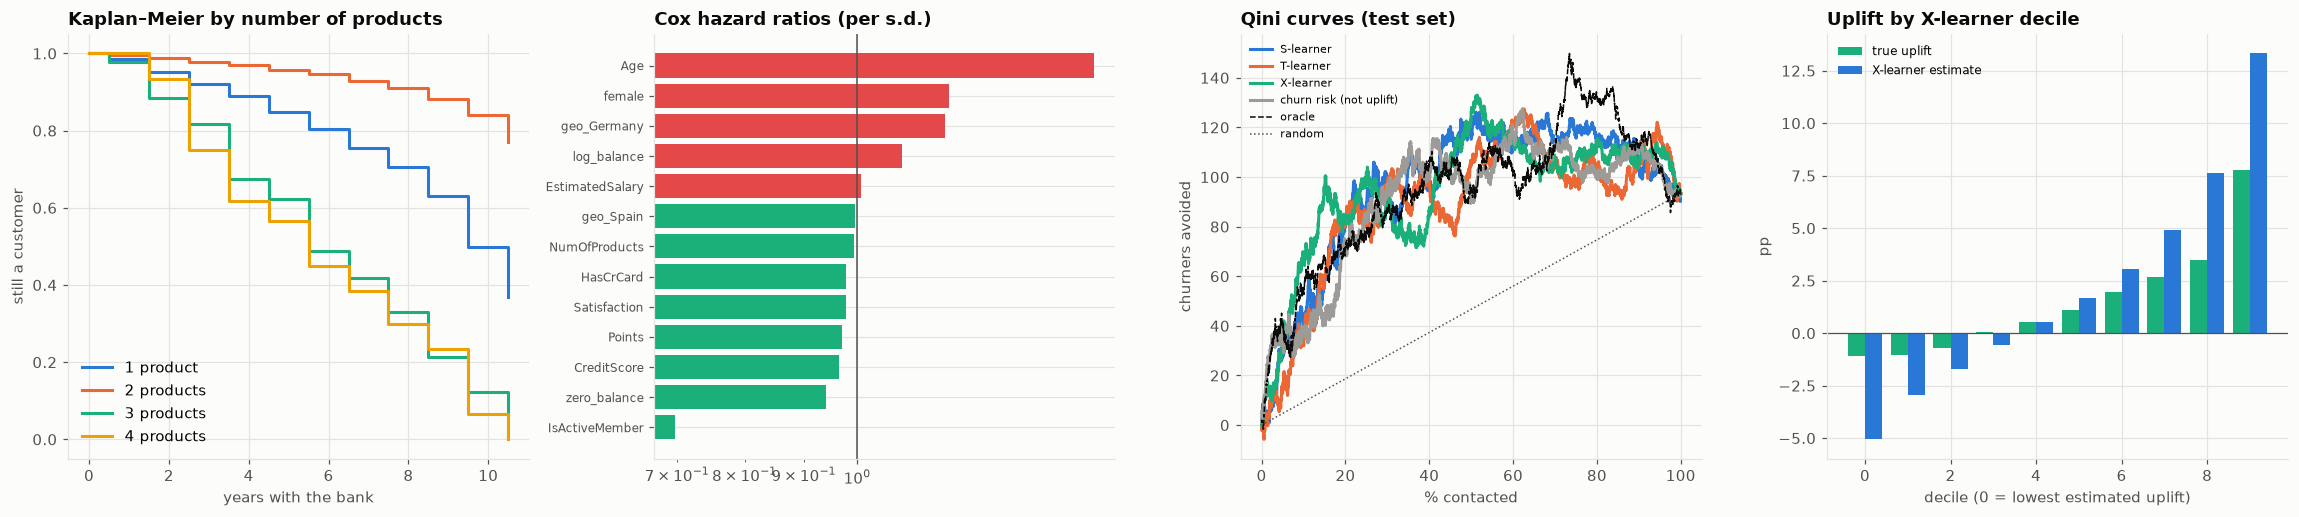

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.8))
ax = axes[0]
for g, col in zip([1, 2, 3, 4], PALETTE):
    m = df["NumOfProducts"] == g
    KaplanMeierFitter().fit(
        df.loc[m, "T"],
        df.loc[m, "Exited"],
        label=f"{g} product{'s' if g > 1 else ''}",
    ).plot_survival_function(ax=ax, ci_show=False, color=col)
ax.set_title("Kaplan–Meier by number of products")
ax.set_xlabel("years with the bank")
ax.set_ylabel("still a customer")
ax = axes[1]
h = hr["hazard ratio per s.d."].sort_values()
ax.barh(
    h.index,
    h.values,
    color=[PALETTE[7] if v > 1 else PALETTE[2] for v in h.values],
)
ax.axvline(1, color=INK_2, lw=1)
ax.set_xscale("log")
ax.set_title("Cox hazard ratios (per s.d.)")
ax.tick_params(axis="y", labelsize=8)
ax = axes[2]
x = np.arange(1, len(t_te) + 1) / len(t_te) * 100
for k, col in zip(est, [PALETTE[0], PALETTE[1], PALETTE[2], "#9c9b97"]):
    ax.plot(x, qini(est[k]), color=col, label=k)
ax.plot(x, qini(true_te), color=INK, ls="--", lw=1, label="oracle")
ax.plot(
    [0, 100], [0, qini(true_te)[-1]], color=INK_2, ls=":", lw=1, label="random"
)
ax.set_title("Qini curves (test set)")
ax.set_xlabel("% contacted")
ax.set_ylabel("churners avoided")
ax.legend(fontsize=7)
ax = axes[3]
dec = pd.qcut(tau_x, 10, labels=False, duplicates="drop")
g = (
    pd.DataFrame({"dec": dec, "true": true_te * 100, "est": tau_x * 100})
    .groupby("dec")
    .mean()
)
ax.bar(g.index - 0.2, g["true"], 0.4, color=PALETTE[2], label="true uplift")
ax.bar(
    g.index + 0.2, g["est"], 0.4, color=PALETTE[0], label="X-learner estimate"
)
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_title("Uplift by X-learner decile")
ax.set_xlabel("decile (0 = lowest estimated uplift)")
ax.set_ylabel("pp")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_survival_cox_qini_uplift")
plt.show()

## 7. Reading the results and limitations

10,000 bank customers, 20.4% of whom left; uplift results come from a campaign simulated on the same customers with a known effect:

- **The leakage audit catches the obvious trap.** `Complain` matches `Exited` for 99.9% of customers (only 14 disagree). It must be recorded at or after exit, and any model using it would score an almost perfect and useless AUC. It is dropped.
- **Survival curves show who leaves and when.**
  - **Geography:** German customers churn at twice the rate of French and Spanish ones (32% vs 16–17%); only 30% are still customers after ten years, against 55–62%.
  - **Number of products** is the strongest and most non-linear pattern. Two products is the sweet spot (77% survive ten years). One product gives 37%, and three or four products almost always lead to exit (83–100% churn), probably forced bundles.
  - **Activity:** inactive members leave much faster (log-rank χ² 179, p ≈ 10⁻⁴¹).

**Cox PH misses the non-linear patterns.** Older customers (hazard ratio 1.60 per standard deviation of age), women (1.20) and German customers (1.19) leave sooner; active members stay longer (0.70). But the number of products gets a hazard ratio of 0.99 because its effect is U-shaped, and a linear Cox term averages it away.

The proportional-hazards test does not reject for the main drivers; it is borderline only for products and Spain (p 0.01–0.05). The **random survival forest** captures the non-linearity: test C-index **0.79** vs 0.71 for Cox, and integrated Brier score 0.12 vs 0.14.

**Targeting by churn risk is not the same as targeting by uplift.** In the simulated trial, persuadables (inactive, one product, positive balance) gain 8 points on average from the offer. Sleeping dogs (active, two products) *lose* 3 points: churn 7.0% in control vs 9.4% when contacted. Ranking customers by churn risk correlates only 0.42 with the true uplift. Contacting the riskiest 30% avoids 44 churns and roughly breaks even (−$260).

- **Uplift learners do better, and the simplest one wins here.** Contacting the top 30% by estimated uplift:
  - S-learner: rank correlation with the true effect 0.71, 62 churns avoided, $6,800 profit;
  - X-learner: 0.59, 56 churns avoided, $4,300;
  - T-learner: 0.49, 52 churns avoided, $2,900;
  - oracle (true uplift): 70 churns avoided, $9,900;
  - random targeting: 18 churns avoided and a $10,900 loss.

With 6,000 training customers and effects of a few points, the T-learner's two separate models are noisy. The X-learner improves on it, and the strongly regularised S-learner is best. The X-learner deciles do sort customers correctly: the bottom three deciles have negative true uplift, the top decile +7.8 points.

**Qini curves on observed outcomes are noisy.** Even the oracle's curve wiggles, because each customer's outcome is a single coin flip. On a real campaign the Qini curve would be the only evidence available, and a sample like this one could not reliably separate the learners. That argues for larger randomised tests or longer campaigns before trusting an uplift model.

**Limitations**

- The treatment and its effects are simulated (the data contain no campaign); the exercise tests the methods, not this bank's customers.
- Tenure is the only time variable and churn timing within the year is unknown, so survival times are interval-censored and treated with a mid-year convention.
- The economics ($15 per contact, $400 of annual margin per retained customer) are illustrative.

In [9]:
km_tab.to_csv(OUT_DIR / "kaplan_meier_segments.csv")
hr.to_csv(OUT_DIR / "cox_hazard_ratios.csv")
surv_eval.to_csv(OUT_DIR / "survival_model_evaluation.csv")
uplift_eval.to_csv(OUT_DIR / "uplift_evaluation.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_survival_cox_qini_uplift.png, cox_hazard_ratios.csv, kaplan_meier_segments.csv, survival_model_evaluation.csv, uplift_evaluation.csv


## References

### Finance and regulation

- Van den Poel, D., & Larivière, B. (2004). Customer attrition analysis for financial services using proportional hazard models. *European Journal of Operational Research, 157*(1), 196–217. https://doi.org/10.1016/S0377-2217(03)00069-9
- Verbeke, W., Dejaeger, K., Martens, D., Hur, J., & Baesens, B. (2012). New insights into churn prediction in the telecommunication sector: A profit driven data mining approach. *European Journal of Operational Research, 218*(1), 211–229. https://doi.org/10.1016/j.ejor.2011.09.031
- Ascarza, E. (2018). Retention futility: Targeting high-risk customers might be ineffective. *Journal of Marketing Research, 55*(1), 80–98. https://doi.org/10.1509/jmr.16.0163

### Machine learning and deep learning

- Kaplan, E. L., & Meier, P. (1958). Nonparametric estimation from incomplete observations. *Journal of the American Statistical Association, 53*(282), 457–481. https://doi.org/10.1080/01621459.1958.10501452
- Cox, D. R. (1972). Regression models and life-tables. *Journal of the Royal Statistical Society: Series B, 34*(2), 187–202. https://doi.org/10.1111/j.2517-6161.1972.tb00899.x
- Ishwaran, H., Kogalur, U. B., Blackstone, E. H., & Lauer, M. S. (2008). Random survival forests. *The Annals of Applied Statistics, 2*(3), 841–860. https://doi.org/10.1214/08-AOAS169
- Künzel, S. R., Sekhon, J. S., Bickel, P. J., & Yu, B. (2019). Metalearners for estimating heterogeneous treatment effects using machine learning. *Proceedings of the National Academy of Sciences, 116*(10), 4156–4165. https://doi.org/10.1073/pnas.1804597116
- Gutierrez, P., & Gérardy, J.-Y. (2017). Causal inference and uplift modelling: A review of the literature. In *Proceedings of the 3rd International Conference on Predictive Applications and APIs* (pp. 1–13). PMLR. https://proceedings.mlr.press/v67/gutierrez17a.html
- Pölsterl, S. (2020). scikit-survival: A library for time-to-event analysis built on top of scikit-learn. *Journal of Machine Learning Research, 21*(212), 1–6. https://jmlr.org/papers/v21/20-729.html